# 03 · Stage 2: a cross-encoder reranker over the top 20

**Goal:** take the 20 candidates per query that the best stage-1 system produces (hybrid search with the fine-tuned
embedding model, notebook 02), re-order them with a cross-encoder, and measure the order of the **top 3**, the
products a shopping assistant would hand to the Large Language Model (LLM). Compare the stage-1 order itself,
two off-the-shelf rerankers, and a reranker fine-tuned on the same judgements the embedding model learned from.

| | |
|---|---|
| Candidates | top 20 per test query from `embed-v1-substitutes-hybrid` (Reciprocal Rank Fusion of BM25 and the fine-tuned bge-base), the same frozen 8,955 queries |
| Rerankers | `cross-encoder/ms-marco-MiniLM-L-6-v2` (22M), `BAAI/bge-reranker-base` (278M), both off the shelf; `bge-reranker-base` fine-tuned on the training judgements (`esci/rerank_train.py`) |
| Metrics | recall@3, hit@3, MRR@3, nDCG@3 for the 3 slots; nDCG@10 as the standard listwise number. recall@20 is fixed by stage 1 and cannot change here. |
| Where it runs | Modal A10G; the laptop launches and reads reports. |

Every cell was executed before this file was committed; Modal cells read saved reports when they exist.

## 1. Why a second stage, and why a cross-encoder rather than a gradient-boosted tree

**Bi-encoder vs cross-encoder.** Stage 1 embeds the query and each product *separately* and compares two vectors,
which is what makes searching 482k products in milliseconds possible, and also what limits it: the product vector
was computed without knowing the query, so "without rims", "non marking", "for 8 month old" have to survive
compression into 768 numbers that must serve every possible query. A **cross-encoder** feeds the query and one
product *together* through a BERT-style model with full attention between every query token and every product
token, and outputs one relevance score. It can check the exact constraint. It is also 20 forward passes per query
instead of one vector comparison, so it only ever sees the short list.

**Where gradient-boosted trees fit.** In production e-commerce search the final ranking stage is very often a
learning-to-rank model built on gradient-boosted decision trees (GBDT, typically LambdaMART in LightGBM or
XGBoost). Those models do not read text. They take a few dozen to a few hundred *features* per (query, product)
pair: the BM25 score, the dense score, the cross-encoder score, price, rating, review count, click-through and
purchase rates, category match, stock, freshness, personalisation signals. Their job is to combine business and
behavioural signals with text relevance, and they are fast, interpretable and easy to retrain daily. The
cross-encoder is the *text-relevance feature* in that stack, usually the single most important one. ESCI has text
and human relevance labels only (no prices, clicks or sales), so the cross-encoder is the stage worth building
here; a LambdaMART over the scores we do have (BM25, dense, cross-encoder, rank positions) is a short, cheap
extension and is noted at the end.

**What the metrics mean here.** With about 9 Exact products per query and 3 slots, recall@3 is capped near 0.33
for most queries; **hit@3** (at least one Exact product in the 3) and **nDCG@3** (graded order, substitutes earn
a little) are the numbers to read. MRR@3 says how often the first slot is right.

In [1]:
import json, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

import esci
from jobs import modal_esci
from jobs.common import modal_once   # runs a Modal job once: a saved outputs/<run>/report.json is read back instead of paying again

PROCESSED, OUT = Path("data/processed/us-small"), Path("outputs")
LOCALE, VERSION = "us", "small"
STAGE1_RUN = "embed-v1-substitutes-hybrid"
CANDIDATES = f"{STAGE1_RUN}/rankings/hybrid(bm25+after).parquet"     # path inside the Modal Volume esci-runs
RERANKER = "BAAI/bge-reranker-base"
MINILM = "cross-encoder/ms-marco-MiniLM-L-6-v2"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9.5})

data = esci.data.load_benchmark(PROCESSED)
text = dict(zip(data["corpus"]["product_id"], data["corpus"]["text"]))
cands = esci.metrics.load_rankings(OUT / STAGE1_RUN / "rankings" / "hybrid(bm25+after).parquet")
qrels = esci.metrics.qrels_from_frame(data["test"])
print(f"stage-1 candidates for {len(cands):,} test queries; depth {len(next(iter(cands.values())))}")

stage-1 candidates for 8,955 test queries; depth 100


## 2. What the reranker sees

One test query, its 20 candidates in stage-1 order, and the label a human gave each one. The reranker's job is to
move the E rows up and the S / I rows down; it never sees the labels, only the query and the product text.

In [2]:
queries = dict(zip(data["test"]["query_id"], data["test"]["query"]))
labels_in_top = lambda q: [qrels[q].get(p, "·") for p in cands[q][:20]]
qid = next(q for q in cands if labels_in_top(q)[0] != "E" and 2 <= labels_in_top(q).count("E") <= 5 and labels_in_top(q).count("·") <= 10)
print(f"query {qid}: {queries[qid]!r}   ({sum(l == 'E' for l in qrels[qid].values())} Exact among {len(qrels[qid])} judged)\n")
for i, p in enumerate(cands[qid][:20], 1):
    print(f"{i:2d} [{qrels[qid].get(p, '·')}] {textwrap.shorten(text[p].replace(chr(10), ' | '), 105)}")
print("\n· = never judged for this query (counts as not relevant)")

query 226: '+outside weather station and not digital'   (12 Exact among 39 judged)

 1 [S] AcuRite Digital Weather Station | Brand: AcuRite | Digital Weather Station For indoor Easy readings [...]
 2 [·] Weather Station Indoor Outdoor Thermometer Wireless Humidity Home Temperature Monitor Weather [...]
 3 [S] Wittime 2081 Weather Stations Wireless Indoor Outdoor Thermometer Wireless Weather Station [...]
 4 [I] Newentor Weather Station Wireless Indoor Outdoor Multiple Sensors, Digital Atomic Clock Weather [...]
 5 [S] Slopehill Weather Station, Wireless Indoor Outdoor Thermometer Hygrometer with Remote Sensor, [...]
 6 [S] Newentor Weather Station Wireless Indoor Outdoor Thermometer, Color Display Digital Weather [...]
 7 [S] Weather Station Wireless Indoor Outdoor Weather Stations with Atomic Clock, Large Display Digital [...]
 8 [S] DOVEET Weather Station Wireless Indoor Outdoor,Weather Forecast Station Thermometer Hygrometer with [...]
 9 [E] Home Weather Stations Wireless Indoor Ou

## 3. Training the reranker

`esci/rerank_train.py` builds pointwise rows from the training judgements: (query, product text, label), label 1 for
Exact and 0 for Substitute / Complement / Irrelevant, up to 4 positives and 8 negatives per query, trained with
binary cross-entropy (`pos_weight` balances the two classes). The negatives are the same human-labelled near
misses that made the difference in notebook 02; for a reranker they are exactly the right distribution, since its
candidates in production are near misses by construction. A listwise alternative (`--loss lambda`, LambdaLoss on
the graded gains) is in the CLI for a later experiment.

Evaluation reranks each test query's 20 candidates and scores the new order with `esci.metrics` at cutoffs 3, 10, 20.
The smoke run first: 500 test queries, 2,000 training queries, 30 steps.

In [3]:
t0 = time.time()
with modal_esci.app.run():
    smoke = modal_once("rerank-smoke", lambda: modal_esci.rerank_train_and_evaluate.remote(
        run_name="rerank-smoke", candidates=CANDIDATES, model=RERANKER, locale=LOCALE, version=VERSION, k=20, epochs=1, lr=2e-5, batch_size=32,
        loss="bce", max_positives_per_query=4, max_negatives_per_query=8, compare=[MINILM], max_steps=30, max_length=320,
        max_test_queries=500, max_train_queries=2000, seed=42))
print(f"done in {(time.time() - t0) / 60:.1f} min")

KEEP = ["recall@3", "hit@3", "mrr@3", "ndcg@3", "ndcg@10", "recall@20"]
def rows(report, gpu="A10G"):
    out = [{"system": label, "params (M)": r["params_M"], **{k: round(r["metrics"][k], 3) for k in KEEP}, "score (s)": r["score_seconds"]}
           for label, r in report["results"].items()]
    secs = report.get("container_seconds", report.get("wall_seconds"))
    extra = f"training {report['metrics']['wall_seconds']:.0f}s on {report['training_data']['rows']:,} rows | " if "metrics" in report else ""
    print(f"{report['run_name']:18s} {extra}container {secs:5.0f}s on {gpu} ≈ ${modal_esci.est_cost(secs, gpu):.3f}")
    return out
pd.DataFrame(rows(smoke)).set_index("system")

rerank-smoke: using the saved report at outputs/rerank-smoke/report.json
done in 0.0 min
rerank-smoke       training 16s on 19,870 rows | container    71s on A10G ≈ $0.022


,params (M),recall@3,hit@3,mrr@3,ndcg@3,ndcg@10,recall@20,score (s)
system,,,,,,,,
stage-1 order (no reranker),0.0,0.201,0.652,0.558,0.433,0.403,0.48,0.0
before,278.0,0.193,0.658,0.549,0.429,0.407,0.48,8.8
after,278.0,0.172,0.620,0.501,0.383,0.377,0.48,8.2
cross-encoder/ms-marco-MiniLM-L-6-v2,22.7,0.207,0.646,0.560,0.453,0.420,0.48,2.4


## 4. The full runs

Two jobs in parallel on A10Gs: the fine-tune of `bge-reranker-base` for one epoch (with its off-the-shelf score
measured first), and the off-the-shelf MiniLM reranker plus the stage-1 order on the full 8,955 queries.

In [4]:
t0 = time.time()
with modal_esci.app.run():
    jobs = {}
    if not (OUT / "rerank-v1" / "report.json").exists():
        jobs["rerank-v1"] = modal_esci.rerank_train_and_evaluate.spawn(
            run_name="rerank-v1", candidates=CANDIDATES, model=RERANKER, locale=LOCALE, version=VERSION, k=20, epochs=1, lr=2e-5, batch_size=64,
            loss="bce", max_positives_per_query=3, max_negatives_per_query=5, max_length=320, seed=42)
    if not (OUT / "rerank-offtheshelf" / "report.json").exists():
        jobs["rerank-offtheshelf"] = modal_esci.rerank_train_and_evaluate.spawn(
            run_name="rerank-offtheshelf", candidates=CANDIDATES, model=RERANKER, locale=LOCALE, version=VERSION, k=20, epochs=1, lr=2e-5, batch_size=32,
            loss="bce", max_positives_per_query=3, max_negatives_per_query=5, compare=[MINILM], eval_only=True, max_length=320, seed=42)
    tuned = modal_once("rerank-v1", lambda: jobs["rerank-v1"].get())
    ots = modal_once("rerank-offtheshelf", lambda: jobs["rerank-offtheshelf"].get())
print(f"done in {(time.time() - t0) / 60:.1f} min\n")
full = pd.DataFrame(rows(ots) + rows(tuned)).set_index("system")
full

rerank-v1: using the saved report at outputs/rerank-v1/report.json
rerank-offtheshelf: using the saved report at outputs/rerank-offtheshelf/report.json
done in 0.0 min

rerank-offtheshelf container    63s on A10G ≈ $0.019
rerank-v1          training 862s on 144,806 rows | container  1214s on A10G ≈ $0.371


,params (M),recall@3,hit@3,mrr@3,ndcg@3,ndcg@10,recall@20,score (s)
system,,,,,,,,
stage-1 order (no reranker),0.0,0.181,0.621,0.520,0.408,0.383,0.464,0.5
cross-encoder/ms-marco-MiniLM-L-6-v2,22.7,0.193,0.651,0.550,0.435,0.403,0.464,45.2
stage-1 order (no reranker),0.0,0.181,0.621,0.520,0.408,0.383,0.464,0.5
before,278.0,0.187,0.648,0.537,0.421,0.396,0.464,149.6
after,278.0,0.203,0.659,0.567,0.451,0.414,0.464,156.1


## 5. Results: the final list

In [5]:
NAMES = {"stage-1 order (no reranker)": "stage-1 order: hybrid BM25 + fine-tuned bge-base", MINILM: "MiniLM-L-6 MS MARCO reranker, off the shelf",
         "before": "bge-reranker-base, off the shelf", "after": "bge-reranker-base, fine-tuned on ESCI judgements"}
results = pd.DataFrame([
    {"system": NAMES[k], "params (M)": r["params_M"], **{m: round(r["metrics"][m], 3) for m in KEEP}}
    for rep in (ots, tuned) for k, r in rep["results"].items() if k in NAMES and not (rep is tuned and k == "stage-1 order (no reranker)")
]).set_index("system")
results

,params (M),recall@3,hit@3,mrr@3,ndcg@3,ndcg@10,recall@20
system,,,,,,,
stage-1 order: hybrid BM25 + fine-tuned bge-base,0.0,0.181,0.621,0.520,0.408,0.383,0.464
"MiniLM-L-6 MS MARCO reranker, off the shelf",22.7,0.193,0.651,0.550,0.435,0.403,0.464
"bge-reranker-base, off the shelf",278.0,0.187,0.648,0.537,0.421,0.396,0.464
"bge-reranker-base, fine-tuned on ESCI judgements",278.0,0.203,0.659,0.567,0.451,0.414,0.464


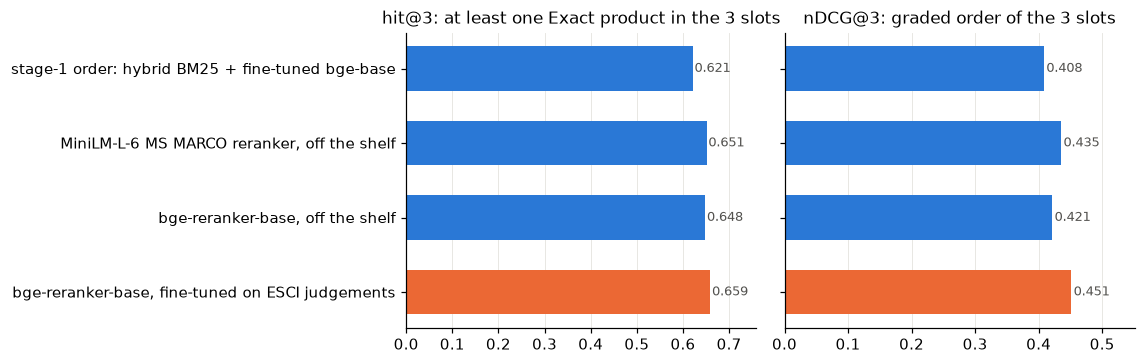

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 0.5 * len(results) + 1.4))
for ax, metric, title in ((axes[0], "hit@3", "hit@3: at least one Exact product in the 3 slots"), (axes[1], "ndcg@3", "nDCG@3: graded order of the 3 slots")):
    y = np.arange(len(results))
    colors = [ORANGE if "fine-tuned on ESCI" in s else BLUE for s in results.index]
    ax.barh(y, results[metric], height=0.6, color=colors)
    for yy, v in zip(y, results[metric]):
        ax.text(v + 0.004, yy, f"{v:.3f}", va="center", fontsize=8.5, color="#52514e")
    ax.set(yticks=y, yticklabels=results.index if ax is axes[0] else [""] * len(results), xlim=(0, results[metric].max() + 0.1), title=title)
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

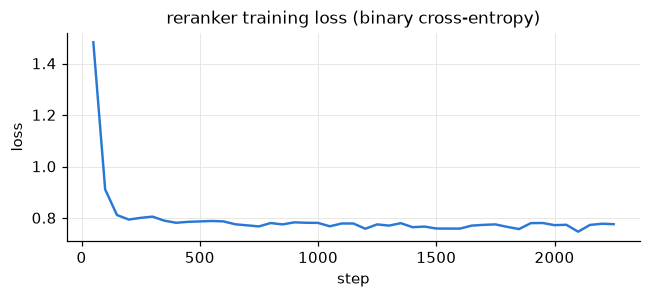

{'eval_dev_map': 0.7298436376136815, 'eval_dev_mrr@3': 0.8326666666666667, 'eval_dev_ndcg@3': 0.7371508217295952}
training data: {'rows': 144806, 'positives': 54447, 'negatives': 90359, 'queries': 20039, 'listwise': False}


In [7]:
# Training curve and dev-set reranking metric per epoch.
hist = pd.DataFrame(tuned["log_history"])
tr = hist.dropna(subset=["loss"])
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(tr["step"], tr["loss"], color=BLUE, linewidth=1.6)
ax.set(title="reranker training loss (binary cross-entropy)", xlabel="step", ylabel="loss")
plt.tight_layout(); plt.show()
ev = hist.dropna(subset=[c for c in hist.columns if c.startswith("eval_dev") and "ndcg" in c][:1])
print({k: v for k, v in ev.iloc[-1].items() if k.startswith("eval_dev")} if len(ev) else "no dev evaluation logged")
print("training data:", tuned["training_data"])

## 6. Per-query view: what the reranker fixes and what it breaks

In [8]:
pq = {}
for run, label, col in (("rerank-offtheshelf", "stage-1 order (no reranker)", "stage1"), ("rerank-offtheshelf", MINILM.replace("/", "__"), "minilm"),
                        ("rerank-v1", "before", "bge_rr_base"), ("rerank-v1", "after", "tuned")):
    pq[col] = pd.read_parquet(OUT / run / "rankings" / f"{label}.per_query.parquet").set_index("query_id")[["hit@3", "ndcg@3"]].add_prefix(col + " ")
pq = pd.concat(pq.values(), axis=1)
pq["query"] = pd.Series(queries)
pq["n_exact"] = data["test"][data["test"].esci_label == "E"].groupby("query_id").size()
d = pq["tuned hit@3"] - pq["stage1 hit@3"]
print(f"fine-tuned reranker vs stage-1 order, hit@3 per query: fixes {(d > 0).mean():.1%}, breaks {(d < 0).mean():.1%}, same {(d == 0).mean():.1%}")
dn = pq["tuned ndcg@3"] - pq["stage1 ndcg@3"]
print(f"                                     nDCG@3 per query: better {(dn > 0).mean():.1%}, worse {(dn < 0).mean():.1%}, same {(dn == 0).mean():.1%}")
has_e20 = pd.Series({q: any(qrels[q].get(p) == "E" for p in c[:20]) for q, c in cands.items()})
print(f"queries with at least one Exact product among the 20 candidates (the ceiling for hit@3): {has_e20.mean():.1%}")
pd.set_option("display.max_colwidth", 60)
print("\nfixed by the fine-tuned reranker (no Exact in the first 3 → Exact in the first 3), a random sample:")
display(pq[d > 0].sample(8, random_state=1)[["query", "n_exact", "stage1 ndcg@3", "tuned ndcg@3"]].round(2))
print("broken by it, a random sample:")
pq[d < 0].sample(8, random_state=1)[["query", "n_exact", "stage1 ndcg@3", "tuned ndcg@3"]].round(2)

fine-tuned reranker vs stage-1 order, hit@3 per query: fixes 10.8%, breaks 6.9%, same 82.3%
                                     nDCG@3 per query: better 35.3%, worse 25.9%, same 38.8%
queries with at least one Exact product among the 20 candidates (the ceiling for hit@3): 82.5%

fixed by the fine-tuned reranker (no Exact in the first 3 → Exact in the first 3), a random sample:


,query,n_exact,stage1 ndcg@3,tuned ndcg@3
query_id,,,,
22491,canon t8i battery,3,0.03,0.28
100845,tattoo gun,7,0.05,0.32
50434,hidden shelves,6,0.00,0.77
56134,john deere d140 drive belt,3,0.10,0.52
37789,entertainment stand for tv up to 90,1,0.00,1.00
25088,cheap jean jumper for woman,11,0.00,0.49
105170,trees for planting outdoors,29,0.00,0.30
26054,christmas table cover,12,0.00,0.53


broken by it, a random sample:


,query,n_exact,stage1 ndcg@3,tuned ndcg@3
query_id,,,,
55454,jansport big student backpack,9,0.53,0.0
28198,compact projector,15,0.77,0.0
34443,dog hip joint c.f.,7,0.23,0.0
51221,hoodies for men with designs,10,0.47,0.0
1444,100% all natural male enhancement without caffeine,22,0.30,0.0
5728,I'm looking for a fully waterproof and windproof jacket ...,12,0.23,0.0
83910,ps4 capture card,14,0.23,0.0
55935,jewelry for girls,11,0.23,0.0


## 7. The pipeline end to end, and what is next

Three stages, each judged on its own job and each trained on the same human judgements:

| Stage | System | Judged on | Result |
|---|---|---|---|
| 1. Retrieval over 482k products | hybrid BM25 + fine-tuned bge-base | recall@20 | 0.464 (base model alone: 0.421; Qwen3-8B: 0.455) |
| 2. Rerank the 20 | see §5 | hit@3, nDCG@3 | see §5 |
| 3. Answer | LLM over the 3 products | not measured here | – |

Next steps, in order of expected value per dollar:

- **A LambdaMART over the scores** (LightGBM, CPU, minutes): features per (query, product) = BM25 score and rank,
  dense score and rank, cross-encoder score, title length, has-brand. On ESCI it can only combine what the three
  retrievers already know, but it is the shape production rankers have and it answers the "isn't it just GBDT"
  question with a number.
- **Listwise training** (`--loss lambda`) on the graded labels, so Substitutes are ranked above Irrelevants
  rather than treated as equally wrong.
- **Hard candidates from stage 1 for training**: rerank training rows drawn from the fine-tuned retriever's own
  top-20 on training queries (with labels where they exist) instead of the judged lists only.

## 8. Gotchas

- **A reranker cannot fix recall.** If stage 1 did not retrieve it, no reranking brings it back; hit@3 is capped by
  the share of queries with an Exact product among the 20 (printed in §6).
- **Off-the-shelf rerankers were trained on web question answering (MS MARCO).** Shopping queries are three
  words of nouns; "relevance" there is attribute matching, not answering. Do not assume a strong leaderboard
  reranker transfers.
- **Pointwise binary labels throw away the grades.** Substitute and Irrelevant are both 0 under binary
  cross-entropy; nDCG with graded gains rewards a model that knows the difference.
- **Score reranking pairs in half precision**, not training: 179k pairs at 320 tokens take a few minutes either
  way, but fp16 inference halves it.